# Forecasting shear S/N as a function of seeing (SOAR SIFS)

**What this notebook shows.** Given a galaxy's spectrum, its position, a night and the shear you expect, KINO returns the **shear signal-to-noise as a function of seeing**, with the moon, airmass, atmospheric extinction, sky spectrum and seeing scaling all worked out for that night.

$$\text{input: spectrum table, (RA, Dec), night, } g \;\longrightarrow\; \text{output: } \frac{S}{N}(\text{seeing}) \text{ at each time of the night}$$

**How it is computed.** For each (time, seeing) point the pipeline builds the instrument as it would be at that moment (seeing PSF at the line's wavelength and airmass, the sky spectrum as electrons per channel, the dimmed line flux), renders the galaxy through the *same* forward model the inference uses, and computes the **Fisher (Cramer-Rao) information** on $(g_1, g_2)$ from the whole cube (flux image, velocity and dispersion together), marginalising over the nuisance parameters (inclination, PA, size, Sersic index, $v_\mathrm{flat}$, rotation-curve turnover, centroid, systemic velocity, dispersion, line flux) under priors:

$$F_{ij}=\sum_{\text{voxels}}\frac{\partial\mu}{\partial\theta_i}\frac{\partial\mu}{\partial\theta_j}\left(\frac{1}{v}+\frac{1}{2v^2}\right)+F^\text{prior}_{ij},\qquad \sigma_{g_1}^2=\left(F^{-1}\right)_{g_1g_1},\quad v=\mu+\sigma_\text{read}^2 .$$

It takes a few seconds per point instead of the many minutes a nested-sampling run needs, which is what makes ranking hundreds of targets over a semester feasible. Section 6 shows it against real fits.

> **Read this before using any number.** This is a **statistical bound for a perfect model**: the mock galaxy is exactly the model family being fitted, so the data pin every nuisance parameter far below its prior and the shear comes out to a few $10^{-3}$ per galaxy. Real galaxies have non-circular motions, thickness, warps and an uncertain PSF, which set a floor this bound does not contain. The plots therefore show the statistical S/N *and* the S/N with an **assumed intrinsic floor** of 0.03 per galaxy (the README's published-forecast target is $\sigma_\epsilon\approx0.02\text{-}0.04$) plus a **10 % PSF-FWHM error**. **The 0.03 is an assumption, not a measurement**; replace it with your own value (`intrinsic_sigma=`).
>
> Also illustrative: the targets are synthetic; the instrument's sky/dark handling is set by the sky model but its absolute efficiency is digitised by eye from a 2016 figure (`kino/config/sifs.yaml` header); the sky model is for Paranal, not Pachon.

In [1]:
import dataclasses
import json
import tempfile
import time
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from kino_style import AQUA, BLUE, INK2, ORANGE, SEQ_BLUES, YELLOW

from kino.analysis.fisher import shear_fisher
from kino.analysis.forecast import ForecastTarget, forecast_ifu, narrowed_ifu
from kino.galaxy import DiscGalaxy
from kino.instruments.base import PSF
from kino.instruments.ifu import IFU
from kino.io.spectrum import LINES, measure_line_flux, read_spectrum
from kino.observing import (
    SOAR,
    SkyConditions,
    SkyLibrary,
    ifu_sky_electron_rate,
    night_window,
    solar_flux,
)

lib = SkyLibrary.load("../data/skycalc")
sifs = IFU.from_config("../kino/config/sifs.yaml")
night = night_window(SOAR, "2026-10-03")
F107 = solar_flux("2026-10")[0]
print(f"night {night.start.iso[:16]} -> {night.end.iso[:16]} UT ({night.duration:.1f})")
print(f"F10.7 = {F107:.0f} s.f.u. (NOAA predicted, Oct 2026)")

FLOOR = 0.03  # ASSUMED intrinsic per-galaxy shear floor -- replace with your own value
PSF_ERROR = 0.10  # assumed fractional error on the PSF FWHM

night 2026-10-04 00:07 -> 2026-10-04 08:52 UT (8.8 h)
F10.7 = 130 s.f.u. (NOAA predicted, Oct 2026)


## 1. From a spectrum table to a line flux

The input is a 1-D spectrum in an ASCII or FITS table: from the Legacy Survey/DESI/SDSS, or a southern survey. The reader is deliberately strict about **units**: a flux column without a unit raises instead of guessing (SDSS/DESI's $10^{-17}\,\mathrm{erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$ convention is a classic silent factor-of-$10^{17}$ error). Wavelengths are treated as vacuum.

Here a synthetic H$\alpha$ spectrum (z = 0.06, integrated flux $3\times10^{-13}$ erg s$^{-1}$ cm$^{-2}$, on a continuum, with noise) is written as a plain text file in DESI units and read back. `measure_line_flux` fits a Gaussian plus a linear continuum and integrates the Gaussian; its quoted error was checked to have unit pull over 60 noise realisations in the test suite.

The measured flux is what the fibre collected. **The whole galaxy's flux is larger**: pass `aperture_correction` when you know the fraction of the galaxy inside the aperture.

measured F(Halpha) = 3.000e-13 erg / (s cm2) +/- 1.2e-17 erg / (s cm2) (injected 3.0e-13)
line S/N 24367
velocity offset -0.0 km / s, sigma 110 km / s


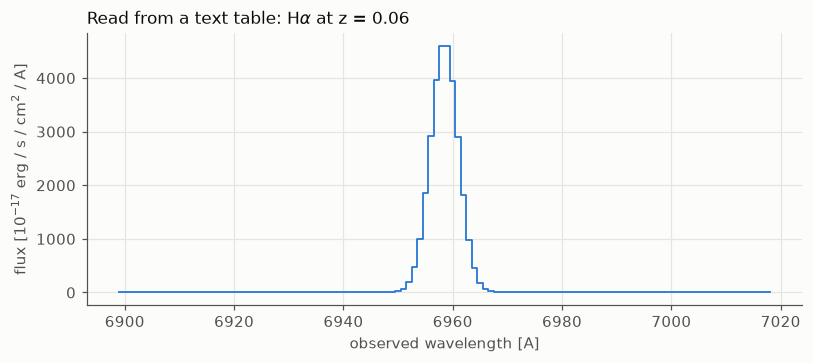

In [2]:
Z_A = 0.06
rng = np.random.default_rng(7)
lam = np.arange(6000.0, 8000.0, 1.0)  # Angstrom
mu = LINES["Halpha"] * (1 + Z_A)
sig = mu * 110.0 / 299792.458
true_flux = 3e-13  # erg/s/cm2
y = true_flux / (sig * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((lam - mu) / sig) ** 2)
y += 4e-17 + rng.normal(0, 3e-18, lam.size)  # continuum + noise, erg/s/cm2/A

path = Path(tempfile.mkdtemp()) / "galaxy_spectrum.txt"
rows = ["# wavelength[Angstrom]  flux[1e-17 erg/s/cm2/A]  error[1e-17 erg/s/cm2/A]"]
rows += [f"{a:.2f} {b / 1e-17:.5f} {0.3:.3f}" for a, b in zip(lam, y, strict=True)]
path.write_text("\n".join(rows) + "\n")

flam17 = 1e-17 * u.erg / u.s / u.cm**2 / u.AA
spec = read_spectrum(path, wavelength_unit="Angstrom", flux_unit=flam17)
m = measure_line_flux(spec, Z_A, "Halpha", aperture_correction=1.0)
print(f"measured F(Halpha) = {m.flux:.3e} +/- {m.flux_err:.1e} (injected {true_flux:.1e})")
print(f"line S/N {m.snr:.0f}")
print(f"velocity offset {m.velocity_offset:.1f}, sigma {m.sigma_velocity:.0f}")

sel = (spec.wavelength.value > mu - 60) & (spec.wavelength.value < mu + 60)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.step(spec.wavelength.value[sel], spec.flux.value[sel], where="mid", color=BLUE, lw=1.2)
ax.set_xlabel("observed wavelength [A]")
ax.set_ylabel("flux [$10^{-17}$ erg / s / cm$^2$ / A]")
ax.set_title(f"Read from a text table: H$\\alpha$ at z = {Z_A}")
fig.tight_layout()

## 2. Three targets

The forecast needs the galaxy's *geometry* as well (from imaging: size, axis ratio, position angle) and its redshift. Three synthetic targets, chosen to bracket the interesting range of line flux:

* **A, bright and extended:** $r_e=3''$, z = 0.06, $F_{\mathrm{H}\alpha}=3\times10^{-13}$ (the flux measured above).
* **B, compact, fainter:** $r_e=1.2''$, z = 0.08, $F_{\mathrm{H}\alpha}=1\times10^{-13}$.
* **C, faint:** $r_e=2''$, z = 0.07, $F_{\mathrm{H}\alpha}=1.5\times10^{-14}$.

All are placed at RA 02h, Dec $-25^\circ$, which transits near local midnight on this date. They are illustrative, not from any proposal list.

In [3]:
coord = SkyCoord("02h00m00s", "-25d00m00s")
flux_unit = u.erg / u.s / u.cm**2
target_a = ForecastTarget(
    coord,
    DiscGalaxy(r_e=3.0, inc=55.0, pa=30.0, v_flat=180.0, z=Z_A, sigma0=30.0),
    m.flux,
    "Halpha",
    name="A (bright, extended)",
)
target_b = ForecastTarget(
    coord,
    DiscGalaxy(r_e=1.2, inc=55.0, pa=30.0, v_flat=180.0, z=0.08, sigma0=30.0),
    1e-13 * flux_unit,
    "Halpha",
    name="B (compact)",
)
target_c = ForecastTarget(
    coord,
    DiscGalaxy(r_e=2.0, inc=55.0, pa=30.0, v_flat=180.0, z=0.07, sigma0=30.0),
    1.5e-14 * flux_unit,
    "Halpha",
    name="C (faint)",
)
TARGETS = [target_a, target_b, target_c]

SEEING = [0.6, 0.8, 1.0, 1.3, 1.7] * u.arcsec  # 500 nm, zenith
G = (0.05, 0.0)  # a cluster-scale shear
t0 = time.time()
fc = {
    t.name: forecast_ifu(
        sifs,
        t,
        night,
        lib,
        g=G,
        seeing_ref=SEEING,
        solar_flux=F107,
        time_step=180 * u.min,
        intrinsic_sigma=FLOOR,
        psf_error=PSF_ERROR,
    )
    for t in TARGETS
}
n_times = len(fc[target_a.name].times)
print(f"three forecasts, {len(SEEING)} seeings x {n_times} times: {time.time() - t0:.0f} s")

three forecasts, 5 seeings x 3 times: 303 s


## 3. Shear S/N against seeing

The headline plot, for a shear of $g=0.05$: for each target the best S/N reached at any time in the night, against the seeing (quoted at 500 nm, zenith). The total error adds, in quadrature, the statistical error, an intrinsic floor and the shear bias from a 10 % PSF-FWHM error:

$$\sigma_\text{total}^2=\sigma_\text{stat}(\text{seeing})^2+\sigma_\text{floor}^2+b_\text{PSF}(\text{seeing})^2 .$$

* **Left, statistical only** (a perfect model). Tens for the bright targets, about 5 for the faint one, falling steadily with worse seeing because the PSF smears the velocity gradients the shear distorts.
* **Middle, floor 0.03.** The S/N is capped near $g/0.03\approx1.7$ for every target and the seeing dependence disappears into the floor.
* **Right, floor 0.005.** If the real floor were ten times smaller, the seeing dependence would return.

The lesson is a *rule*, not a number: **seeing matters where $\sigma_\text{stat}(\text{seeing})$ is comparable to or larger than the floor.** With the statistical errors here (a few $10^{-3}$ per galaxy) that is only true if the real intrinsic floor is a few $10^{-3}$ or less, or for targets much fainter than these. Measuring the floor is therefore the first thing to do: it decides whether a seeing requirement is worth asking for. The number of galaxies for a 5-sigma stack, $(5/\mathrm{S/N}_1)^2$, is printed below.

A (bright, extended)
   stat S/N  [30.4 28.6 26.9 24.2 21. ]
   total S/N (floor 0.03) [1.66 1.66 1.66 1.66 1.64]  -> 5-sigma stack: [9. 9. 9. 9. 9.] galaxies
B (compact)
   stat S/N  [23.4 21.2 19.2 16.5 13.4]
   total S/N (floor 0.03) [1.66 1.65 1.64 1.57 1.54]  -> 5-sigma stack: [ 9.  9.  9. 10. 11.] galaxies
C (faint)
   stat S/N  [5.7 5.3 5.  4.5 3.9]
   total S/N (floor 0.03) [1.6  1.59 1.57 1.54 1.47]  -> 5-sigma stack: [10. 10. 10. 11. 12.] galaxies


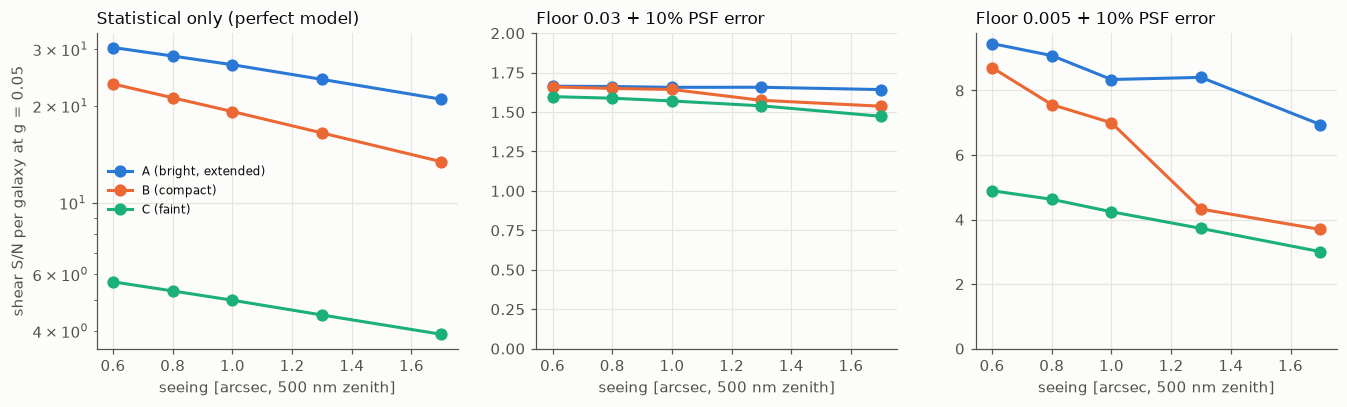

In [4]:
def total_snr(f, floor):
    # S/N along g = (g1, 0) from the stored statistical sigma, the PSF bias and a floor
    stat = f.sigma_g[..., 0]
    psf = np.hypot(f.psf_bias[..., 0], f.psf_bias[..., 1])
    return G[0] / np.sqrt(stat**2 + floor**2 + np.nan_to_num(psf) ** 2)


fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
colors = [BLUE, ORANGE, AQUA]
for (name, f), c in zip(fc.items(), colors, strict=True):
    axes[0].plot(SEEING.value, np.nanmax(f.shear_snr_stat, axis=0), "o-", color=c, label=name)
    axes[1].plot(SEEING.value, np.nanmax(total_snr(f, FLOOR), axis=0), "o-", color=c)
    axes[2].plot(SEEING.value, np.nanmax(total_snr(f, 0.005), axis=0), "o-", color=c)
axes[0].set_yscale("log")
axes[0].set_title("Statistical only (perfect model)")
axes[1].set_title(f"Floor {FLOOR} + {PSF_ERROR:.0%} PSF error")
axes[2].set_title("Floor 0.005 + 10% PSF error")
for a in axes:
    a.set_xlabel("seeing [arcsec, 500 nm zenith]")
axes[0].set_ylabel(f"shear S/N per galaxy at g = {G[0]}")
axes[1].set_ylim(0, 2)
axes[2].set_ylim(0, None)
axes[0].legend(fontsize=8)
fig.tight_layout()
for name, f in fc.items():
    s_stat = np.nanmax(f.shear_snr_stat, axis=0)
    s_tot = np.nanmax(total_snr(f, FLOOR), axis=0)
    n5 = np.round((5.0 / s_tot) ** 2, 0)
    print(name)
    print(f"   stat S/N  {np.round(s_stat, 1)}")
    print(f"   total S/N (floor {FLOOR}) {np.round(s_tot, 2)}  -> 5-sigma stack: {n5} galaxies")

## 4. When to observe

The same forecast resolved in time, for the faint target C at 1.0 arcsec seeing (the statistical S/N, since that is what depends on the night). The target rises, transits and sets; the S/N follows the airmass, the extinction, the seeing at that airmass and the sky. On this date the moon is below the horizon for most of the night and rises near the end (illumination ~ 40 %), which the sky model accounts for.

best time: 2026-10-04 06:07 UT, airmass 1.01


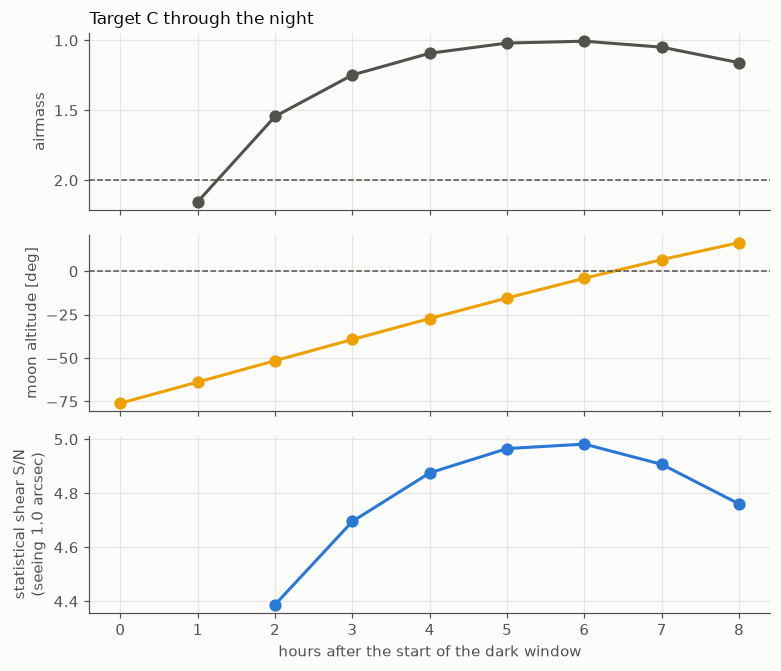

In [5]:
t_fine = forecast_ifu(
    sifs,
    target_c,
    night,
    lib,
    g=G,
    seeing_ref=[1.0] * u.arcsec,
    solar_flux=F107,
    time_step=60 * u.min,
)
hours = (t_fine.times - night.start).to_value(u.hour)
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(7.2, 6.2), sharex=True)
ok = np.isfinite(t_fine.airmass) & (t_fine.airmass < 3.0)
a1.plot(hours[ok], t_fine.airmass[ok], "o-", color=INK2)
a1.axhline(2.0, color=INK2, ls="--", lw=1)
a1.invert_yaxis()
a1.set_ylabel("airmass")
a1.set_title("Target C through the night")
a2.plot(hours, t_fine.moon_altitude.value, "o-", color=YELLOW)
a2.axhline(0, color=INK2, ls="--", lw=1)
a2.set_ylabel("moon altitude [deg]")
a3.plot(hours, t_fine.shear_snr_stat[:, 0], "o-", color=BLUE)
a3.set_xlabel("hours after the start of the dark window")
a3.set_ylabel("statistical shear S/N\n(seeing 1.0 arcsec)")
fig.tight_layout()
best = t_fine.best_time_index(0)
print(f"best time: {t_fine.times[best].iso[:16]} UT, airmass {t_fine.airmass[best]:.2f}")

## 5. What limits the precision?

A flux scan for target A at fixed conditions (dark sky, airmass 1.1, seeing 1.0 arcsec). Three things are drawn:

* the **statistical** $\sigma_{g_1}$ with the nuisance parameters known (blue) and marginalised (orange). Both fall roughly as $F^{-1}$ at low flux, faster than the $F^{-1/2}$ of a photon-limited measurement, because with 0.3 arcsec spaxels and one hour the per-channel signal is only tens of electrons against about 7 e$^-$ of read noise;
* the **assumed intrinsic floor** (shaded, 0.02-0.04);
* the shear bias from a **10 % PSF error** (dashed).

Where the orange curve crosses the floor is the flux above which more signal buys nothing: the measurement is limited by what the model cannot describe, not by photons. For a 0.03 floor and target A that is at a line flux of roughly $3\times10^{-15}$ erg s$^{-1}$ cm$^{-2}$: essentially every target one would propose for is already above it. (A smaller real floor moves the crossing to higher flux.) The PSF-bias curve is not smooth in flux (it is the result of a nonlinear fit of a mis-specified model): read it as an order-of-magnitude estimate, a few $10^{-3}$.

F = 3e-15: sigma_g1 known 0.0165  marginal 0.0271  PSF-bias 0.0015
F = 1e-14: sigma_g1 known 0.0056  marginal 0.0157  PSF-bias 0.0020
F = 3e-14: sigma_g1 known 0.0023  marginal 0.0084  PSF-bias 0.0018
F = 1e-13: sigma_g1 known 0.0010  marginal 0.0037  PSF-bias 0.0010
F = 3e-13: sigma_g1 known 0.0005  marginal 0.0018  PSF-bias 0.0042
F = 1e-12: sigma_g1 known 0.0002  marginal 0.0009  PSF-bias 0.0009


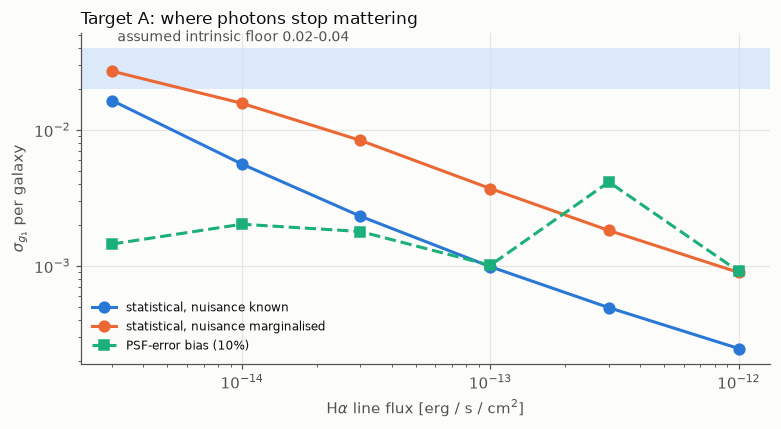

In [6]:
ifu_w = narrowed_ifu(sifs, target_a.observed_wavelength, 500.0)
cond = SkyConditions(1.1, F107)
ifu_w = dataclasses.replace(
    ifu_w,
    psf=PSF(seeing_fwhm=1.0 * u.arcsec),
    sky_electron_rate=ifu_sky_electron_rate(ifu_w, cond, lib),
)
fluxes = np.array([3e-15, 1e-14, 3e-14, 1e-13, 3e-13, 1e-12])
rows = []
for fl in fluxes:
    r = shear_fisher(
        ifu_w,
        target_a.galaxy,
        line_flux=fl * flux_unit,
        line_wavelength=target_a.rest_wavelength,
        g=G,
        psf_error=PSF_ERROR,
    )
    rows.append((fl, r.sigma_fixed[0], r.sigma_marginal[0], float(np.hypot(*r.psf_bias))))
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(rows[:, 0], rows[:, 1], "o-", color=BLUE, label="statistical, nuisance known")
ax.plot(rows[:, 0], rows[:, 2], "o-", color=ORANGE, label="statistical, nuisance marginalised")
ax.plot(rows[:, 0], rows[:, 3], "s--", color=AQUA, label=f"PSF-error bias ({PSF_ERROR:.0%})")
ax.axhspan(0.02, 0.04, color=SEQ_BLUES[0], alpha=0.7, lw=0)
ax.text(rows[0, 0] * 1.05, 0.045, "assumed intrinsic floor 0.02-0.04", color=INK2, fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("H$\\alpha$ line flux [erg / s / cm$^2$]")
ax.set_ylabel("$\\sigma_{g_1}$ per galaxy")
ax.set_title("Target A: where photons stop mattering")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
for fl, sf, sm, pb in rows:
    print(f"F = {fl:.0e}: sigma_g1 known {sf:.4f}  marginal {sm:.4f}  PSF-bias {pb:.4f}")

## 6. Is the forecast right? Real fits say...

A forecast is only as good as its calibration. Its Cramer-Rao bound was compared with real fits of the very likelihood the inference uses, on many noise realisations of the same galaxy: the **scatter** of the recovered shear should equal the forecast $\sigma$, the **bias** should be zero, and (for a sampler) the **pull** $(g_\mathrm{rec}-g_\mathrm{true})/\sigma_\mathrm{posterior}$ should have standard deviation 1. All numbers are in `notebooks/data/fisher_validation.json`, produced by `scripts/validate_fisher_forecast.py` (nested sampling) and `scripts/validate_fisher_mle.py` (maximum likelihood).

**The cube estimator passes.** Nested sampling on a small IFU (24 runs): bias consistent with zero, scatter equal to the Fisher $\sigma$, pull standard deviation 1.06 and 0.93. Maximum-likelihood fits with inclination, PA and $v_\mathrm{flat}$ free (24 realisations each, four setups spanning a factor 6 in line flux): scatter / forecast between 0.97 and 1.65 (mostly below 1.3), bias within about 2 standard errors of zero.

**The moment-map estimator does not, and finding that changed the pipeline.** The first version of the likelihood fitted flux-weighted velocity and dispersion *moment maps*. Validation showed two separate problems, both fixed or documented:

1. *A bug in the background estimate* (fixed): a per-spaxel median inside a narrow spectral window landed in the line's wings, making the dispersion errors 4.6 times too small and the pull 3.3. The known sky-plus-dark baseline is now subtracted instead.
2. *Noise bias* (not fixable analytically): data moments are ratios of noisy sums, the model's are noiseless, so the recovered shear is biased by about one sigma per galaxy and grows toward low S/N; the scatter also exceeds the bound at low S/N. A stack does not average that away. This is why the default estimator is now the cube.

In [7]:
val = json.loads(Path("data/fisher_validation.json").read_text())
ns = val["nested_sampling_cube"]
print(f"nested sampling, cube likelihood (n = {ns['n']}):")
print(f"   bias {ns['mean_bias']} +/- {ns['mean_bias_err']}")
print(f"   scatter {ns['scatter']}  posterior width {ns['mean_posterior_sigma']}")
print(f"   Fisher forecast {ns['fisher_sigma_fixed']}")
print(f"   pull std {ns['pull_std']}  pull mean {ns['pull_mean']}")
print()
print(f"{'MLE, cube, inc/pa/v_flat free':52s} scatter/Fisher      bias/scatter")
for r in val["mle_cube_with_nuisance"]:
    ratio = np.round(np.array(r["bias"]) / np.array(r["scatter"]), 2)
    print(f"  {r['label']:50s} {r['scatter_over_fisher']}   {ratio.tolist()}")

nested sampling, cube likelihood (n = 24):
   bias [2e-05, -0.00012] +/- [0.00013, 0.00011]
   scatter [0.00065, 0.00053]  posterior width [0.00062, 0.00057]
   Fisher forecast [0.00063, 0.00058]
   pull std [1.06, 0.93]  pull mean [0.04, -0.21]

MLE, cube, inc/pa/v_flat free                        scatter/Fisher      bias/scatter
  notebook-04 setup, F=5e-15 (inc, pa, v_flat free)  [1.39, 1.65]   [0.21, -0.23]
  notebook-04 setup, F=5e-16 (inc, pa, v_flat free)  [0.97, 1.29]   [-0.2, -0.01]
  SIFS, F=1e-13 (inc, pa, v_flat free)               [1.02, 1.19]   [-0.42, 0.35]
  SIFS, F=3e-14 (inc, pa, v_flat free)               [0.97, 1.24]   [0.08, -0.0]


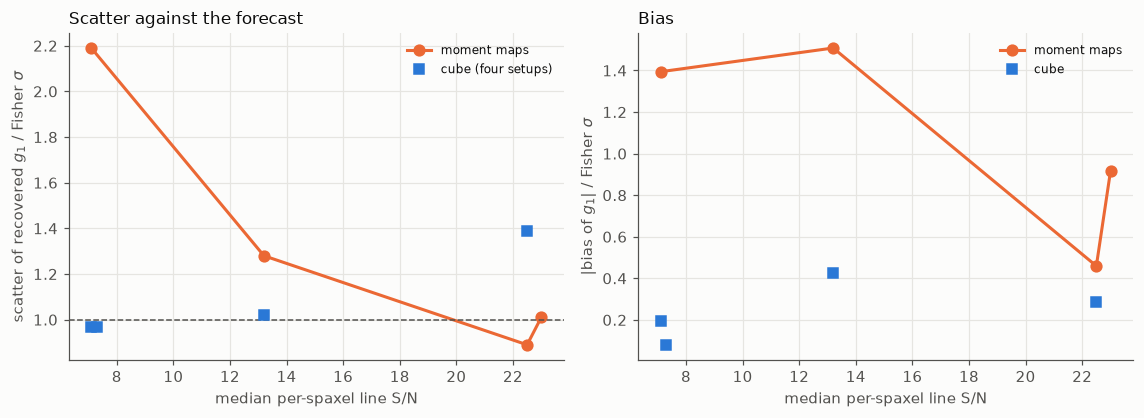

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
mom = [r for r in val["mle_moments"] if "S/N cut" not in r["label"]]
mom = sorted(mom, key=lambda r: r["median_spaxel_snr"])
snr = [r["median_spaxel_snr"] for r in mom]
a1.plot(snr, [r["scatter_over_fisher"][0] for r in mom], "o-", color=ORANGE, label="moment maps")
cube = val["mle_cube_with_nuisance"]
a1.axhline(1.0, color=INK2, lw=1, ls="--")
a1.plot(
    [r["median_spaxel_snr"] for r in cube],
    [r["scatter_over_fisher"][0] for r in cube],
    "s",
    color=BLUE,
    label="cube (four setups)",
)
a1.set_xlabel("median per-spaxel line S/N")
a1.set_ylabel("scatter of recovered $g_1$ / Fisher $\\sigma$")
a1.set_title("Scatter against the forecast")
a1.legend(fontsize=8)
a2.plot(
    snr,
    [abs(r["bias"][0]) / r["fisher_sigma_fixed"][0] for r in mom],
    "o-",
    color=ORANGE,
    label="moment maps",
)
a2.plot(
    [r["median_spaxel_snr"] for r in cube],
    [abs(r["bias"][0]) / r["fisher_sigma_fixed"][0] for r in cube],
    "s",
    color=BLUE,
    label="cube",
)
a2.set_xlabel("median per-spaxel line S/N")
a2.set_ylabel("|bias of $g_1$| / Fisher $\\sigma$")
a2.set_title("Bias")
a2.legend(fontsize=8)
fig.tight_layout()

## 7. Ranking a catalogue

The point of a fast estimator: rank many candidates for a night. Below, eight synthetic targets (random sizes, redshifts, fluxes and positions; **not** from any real list) are forecast at one seeing (1.0 arcsec). For each, the best statistical S/N, the S/N with the assumed floor, and a flag: **`floor`** if the floor already dominates (statistical S/N more than 3 times the total), meaning more exposure or better seeing will not help. Targets that never rise, or whose line falls outside the instrument's tabulated throughput, drop out with a reason. A real run would loop over the candidate table you supply and additionally scan nights.

In [9]:
rng = np.random.default_rng(11)
catalogue = []
for i in range(8):
    z = float(rng.uniform(0.03, 0.10))
    gal = DiscGalaxy(
        r_e=float(rng.uniform(1.0, 4.0)),
        inc=float(rng.uniform(40, 75)),
        pa=float(rng.uniform(0, 180)),
        v_flat=float(rng.uniform(120, 220)),
        z=z,
        sigma0=30.0,
    )
    pos = SkyCoord(f"{rng.uniform(0, 24):.2f}h", f"{rng.uniform(-60, 0):.1f}d")
    flux = float(10 ** rng.uniform(-13.7, -12.3)) * flux_unit
    catalogue.append(ForecastTarget(pos, gal, flux, "Halpha", name=f"T{i + 1}"))

t0 = time.time()
results = []
for t in catalogue:
    try:
        f = forecast_ifu(
            sifs,
            t,
            night,
            lib,
            g=G,
            seeing_ref=[1.0] * u.arcsec,
            solar_flux=F107,
            time_step=120 * u.min,
            intrinsic_sigma=FLOOR,
        )
        stat = float(np.nanmax(f.shear_snr_stat[:, 0]))
        tot = float(np.nanmax(f.shear_snr[:, 0]))
        results.append((t.name, stat, tot, t, "floor" if stat > 3 * tot else "ok"))
    except ValueError as exc:
        results.append((t.name, np.nan, np.nan, t, str(exc)[:50]))
print(f"{len(catalogue)} targets in {time.time() - t0:.0f} s")
results.sort(key=lambda r: -np.nan_to_num(r[2], nan=-1))
head = ("target", "stat S/N", "total S/N", "F(Ha)", "r_e", "z")
print(
    f"{head[0]:6s} {head[1]:>9s} {head[2]:>10s}  {head[3]:>10s}  {head[4]:>5s}  {head[5]:>5s}  note"
)
for name, stat, tot, t, note in results:
    s1 = "   --" if not np.isfinite(stat) else f"{stat:9.1f}"
    s2 = "    --" if not np.isfinite(tot) else f"{tot:10.2f}"
    fl, r_e, zz = t.line_flux.value, t.galaxy.r_e, t.galaxy.z
    print(f"{name:6s} {s1:>9s} {s2:>10s}  {fl:10.2e}  {r_e:5.1f}  {zz:5.3f}  {note}")

8 targets in 31 s
target  stat S/N  total S/N       F(Ha)    r_e      z  note
T2          17.8       1.66    2.53e-13    2.9  0.096  floor
T4          17.7       1.66    4.88e-14    2.8  0.055  floor
T7          14.1       1.66    1.33e-13    4.0  0.041  floor
T8          10.6       1.65    3.01e-14    2.0  0.052  floor
T6           5.0       1.58    2.11e-14    1.6  0.032  floor
T5           4.8       1.57    4.02e-14    3.7  0.036  floor
T3           4.8       1.57    9.49e-14    2.5  0.077  floor
T1           2.0       1.29    3.03e-14    2.5  0.039  ok


## Caveats to carry into any proposal use

* **The floor is an assumption.** Everything that depends on `intrinsic_sigma` (0.03 here) depends on a number nobody has measured for this pipeline. It is the single most important input to replace, ideally from real IFU data or a published KL analysis.
* **Perfect-model statistics.** The un-floored S/N is a bound for data exactly described by `DiscGalaxy`; it says how well *photons* limit the measurement, not what real galaxies allow.
* **Per galaxy.** Stack $N$ comparable galaxies for $\sqrt{N}$ on the statistical part only; the floor may or may not average down (it does if it is random from galaxy to galaxy, not if it is a common bias).
* **Instrument numbers** (see the SIFS config header): absolute efficiency digitised by eye from a 2016 figure; the 700R setting needed for H$\alpha$ at $z>0.11$ has no published efficiency; fibre geometry is modelled as square spaxels.
* **Sky:** Paranal model, not Pachon; airglow is a whole-night mean; solar flux from NOAA's prediction.
* **Extinction** is the CTIO mean, applied on top of an efficiency curve whose definition (does it include the atmosphere?) is not stated; set `include_extinction=False` if it does.
* **Goodman (slit)** is not here: it needs a slit likelihood and the red-camera throughput.